# Phase 10 — Cold-start / unseen-SKU forecasting (Use Case 4)

คำถาม: โมเดลที่ไม่เคยเห็น SKU นี้มาก่อนพยากรณ์ได้ดีแค่ไหนเมื่อเริ่มมีประวัติขาย?

ทดสอบ 5 SKU เปิดตัวล่าสุด: YO-024, MI-008, SN-028, YO-018, SN-030
กันทั้ง 5 SKU ออกจาก train ทุกครั้ง ฝึกโมเดลแยกตาม cutoff ก่อนเปิดตัวแต่ละ SKU
และคงโมเดลไว้ตลอดการทดสอบ (ไม่ retrain) เปรียบเทียบ analog, meta-learner และ full model
บนแถวเดียวกันที่ทุกวิธีมี prediction โดยรายงาน coverage เพิ่มเติม


In [1]:
import sys
sys.path.insert(0, '../../src')

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from models.cold_start import analog_forecast, meta_learner_forecast, mature_model_forecast
from models.metrics import score_all

pd.set_option('display.width', 160)

df = pd.read_csv('../../data/processed/weekly_features.csv', parse_dates=['week'])
daily = pd.read_csv('../../data/raw/FMCG_2022_2024.csv', parse_dates=['date'])
sku_attrs = daily.groupby('sku').agg(
    pack_type=('pack_type', 'first'), segment=('segment', 'first'),
    category=('category', 'first'), price_unit=('price_unit', 'mean'),
    first_seen=('date', 'min'),
)

COLD_START_SKUS = ['YO-024', 'MI-008', 'SN-028', 'YO-018', 'SN-030']
print('Cold-start validation SKUs:', COLD_START_SKUS)


Cold-start validation SKUs: ['YO-024', 'MI-008', 'SN-028', 'YO-018', 'SN-030']


## ขอบเขตและข้อมูลที่ใช้ได้

ตารางนี้เริ่มที่ sku_age=4 เพราะต้องมี rolling history ครบ 4 สัปดาห์ก่อนหน้า
จึงเป็น **short-history / unseen-SKU** ไม่ใช่ zero-history หรือการทำนายก่อนเริ่มขาย
Meta-learner ตัด lag ออกแต่ยังใช้ยอดขายสัปดาห์ปัจจุบันและ demand share ที่ทราบเมื่อจบสัปดาห์
Full model ใช้ประวัติของ SKU ทดสอบ ณ สัปดาห์พยากรณ์ แต่ไม่ใช้ SKU เหล่านั้นฝึกโมเดล

cutoff คือวันจันทร์ของสัปดาห์เปิดตัว (ก่อน first_seen)
แถวฝึกที่ week=W มี label ยอดขายสัปดาห์ W+7 ถึง W+14 จึงใช้ได้เมื่อ W+14 <= cutoff เท่านั้น
โมเดล ML ใช้ vocabulary ของ categorical จาก train เท่านั้น


## 1. Analog-Based Forecast


Analog จับคู่ category+segment แล้วผ่อนเป็น category และราคา ตามลำดับ
ไม่ใช้ pack_type เพราะเปลี่ยนภายใน SKU ใช้ราคาเฉลี่ย candidate จากข้อมูลก่อน cutoff เท่านั้น
ราคา target ใช้ราคาเฉลี่ยวันแรกที่ขายเป็น **proxy ของราคาเปิดตัว** ไม่ใช่หลักฐานว่ารู้อยู่ก่อนเปิดตัว
Analog ใช้ target_next_week ที่อายุเดียวกัน และเฉพาะ trajectory ที่ label ครบก่อน cutoff
จึงอาจไม่มี prediction เมื่ออายุเพิ่มขึ้น ไม่มีการเติมผลจากข้อมูลหลัง cutoff


In [2]:
analog_df = analog_forecast(df, COLD_START_SKUS, sku_attrs, daily=daily)
print(analog_df[['sku', 'analog_sku', 'train_cutoff']].drop_duplicates().to_string(index=False))
print(f'Analog coverage: {analog_df.pred_analog.notna().mean():.1%}')


   sku analog_sku train_cutoff
MI-008     MI-022   2023-04-10
SN-028     SN-019   2023-04-17
SN-030     SN-019   2023-05-22
YO-018     YO-001   2023-05-01
YO-024     YO-016   2023-04-03
Analog coverage: 24.2%


## 2. Meta-Learner Forecast (ตัด lag/rolling ออก แต่ยังใช้ยอดขายสัปดาห์ปัจจุบัน)


In [3]:
meta_df = meta_learner_forecast(df, COLD_START_SKUS)


## 3. Full Model Forecast (มีฟีเจอร์ lag ครบ, ใช้เป็นตัวเทียบ)


In [4]:
full_df = mature_model_forecast(df, COLD_START_SKUS)


## 4. เปรียบเทียบผลตามอายุสินค้า

แสดงอายุจริง sku_age (เริ่มที่ 4) และรวมอายุ >=24 เป็น 24+ อย่างชัดเจน
ทุกวิธีใช้แถวเดียวกันในแต่ละช่วง พร้อมจำนวนแถวและ analog coverage
แถวที่ analog ไม่มี prediction ไม่อยู่ในตารางเปรียบเทียบ แต่รายงานผล ML บนทุกแถวแยกท้าย notebook
ไม่ใช้เส้น Phase 7 เป็นเกณฑ์ตามทัน เพราะคนละ validation protocol


In [5]:
from models.cold_start import launch_week

scored = analog_df[['sku', 'week', 'channel', 'region', 'sku_age', 'target_next_week', 'pred_analog']].copy()
scored['pred_meta_learner'] = meta_df.pred_meta_learner.reindex(scored.index)
scored['pred_full_model'] = full_df.pred_full_model.reindex(scored.index)
pred_cols = ['pred_analog', 'pred_meta_learner', 'pred_full_model']
assert scored[pred_cols[1:]].notna().all().all()
for sku in COLD_START_SKUS:
    cutoff = launch_week(df, sku)
    assert (meta_df.loc[meta_df.sku == sku, 'train_label_available_max'] <= cutoff).all()
    assert (full_df.loc[full_df.sku == sku, 'train_label_available_max'] <= cutoff).all()

scored['age_bucket'] = scored.sku_age.clip(upper=24).astype(int)
common = scored.dropna(subset=pred_cols + ['target_next_week']).copy()
rows = []
for age, available in scored.groupby('age_bucket'):
    shared = common[common.age_bucket == age]
    row = {'sku_age': age, 'age_label': '24+' if age == 24 else str(age),
           'n': len(shared), 'available_n': len(available),
           'coverage': len(shared) / len(available)}
    for label, col in zip(['Analog', 'Meta-learner', 'Full model'], pred_cols):
        row[label] = score_all(shared.target_next_week, shared[col])['WAPE'] if len(shared) else np.nan
    rows.append(row)
curve = pd.DataFrame(rows)
curve.round(3)


,sku_age,age_label,n,available_n,coverage,Analog,Meta-learner,Full model
0,4,4,44,44,1.0,0.276,0.221,0.216
1,5,5,45,45,1.0,0.380,0.242,0.215
2,6,6,45,45,1.0,0.383,0.285,0.267
3,7,7,45,45,1.0,0.460,0.288,0.252
4,8,8,36,45,0.8,0.283,0.306,0.257
5,9,9,36,45,0.8,0.362,0.246,0.228
6,10,10,36,45,0.8,0.277,0.249,0.243
7,11,11,36,45,0.8,0.320,0.293,0.246
8,12,12,36,45,0.8,0.258,0.260,0.246
9,13,13,27,45,0.6,0.348,0.234,0.230


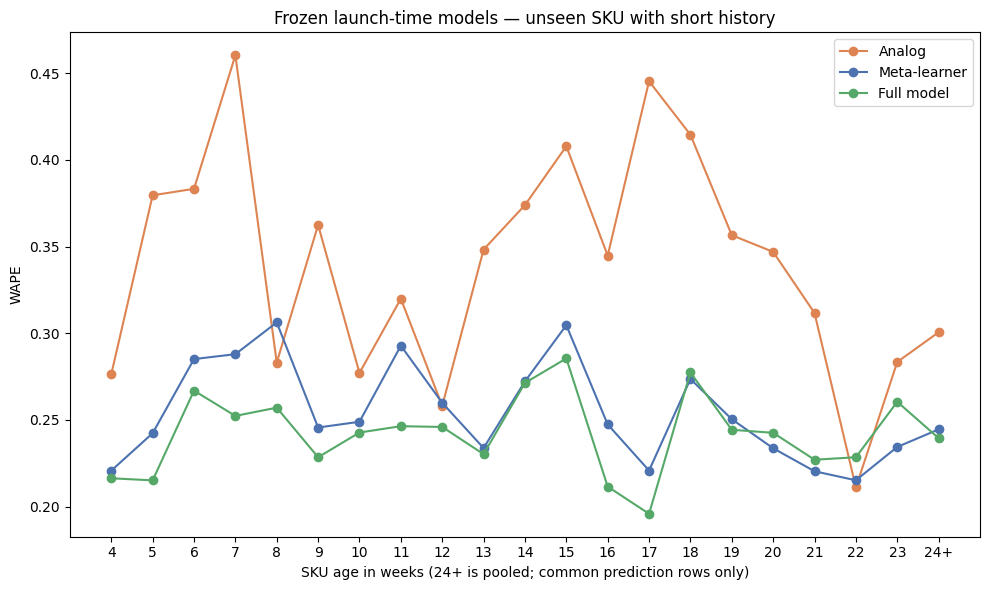

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
for col, color in [('Analog', '#DD8452'), ('Meta-learner', '#4C72B0'), ('Full model', '#55A868')]:
    ax.plot(curve.sku_age, curve[col], marker='o', label=col, color=color)
ax.set_xticks(curve.sku_age)
ax.set_xticklabels(curve.age_label)
ax.set_xlabel('SKU age in weeks (24+ is pooled; common prediction rows only)')
ax.set_ylabel('WAPE')
ax.set_title('Frozen launch-time models — unseen SKU with short history')
ax.legend()
plt.tight_layout()
plt.savefig('../../reports/figures/phase10_cold_start_curve.png', dpi=120)
plt.show()


## 5. ผลสรุปบนแถวเดียวกัน

ช่วงอายุ 4–11 เทียบกับ 12+ (ไม่ใช่สัปดาห์แรกก่อนมีประวัติ)
coverage ต่ำหมายถึงผลเป็นเพียง subset และใช้สรุปแทนทุกแถวไม่ได้


In [7]:
summary_rows = []
for label, lower, upper in [('age 4-11 (short history)', 4, 12), ('age 12+', 12, np.inf)]:
    available = scored[(scored.sku_age >= lower) & (scored.sku_age < upper)]
    shared = common[(common.sku_age >= lower) & (common.sku_age < upper)]
    row = {'window': label, 'n': len(shared), 'available_n': len(available),
           'coverage': len(shared) / len(available)}
    for name, col in zip(['Analog WAPE', 'Meta-learner WAPE', 'Full model WAPE'], pred_cols):
        row[name] = score_all(shared.target_next_week, shared[col])['WAPE'] if len(shared) else np.nan
    summary_rows.append(row)
summary = pd.DataFrame(summary_rows)
summary.round(3)


,window,n,available_n,coverage,Analog WAPE,Meta-learner WAPE,Full model WAPE
0,age 4-11 (short history),323,359,0.900,0.344,0.269,0.242
1,age 12+,594,3427,0.173,0.327,0.248,0.242


## 6. ผลราย SKU และผล ML บนทุกแถว

ตารางด้านล่างช่วยตรวจว่าผลรวมถูกครอบงำด้วย SKU ใดหรือไม่
WAPE เป็นผลเชิงพรรณนา ยังไม่มี confidence interval หรือการทดสอบนัยสำคัญ
ML บนทุกแถวเป็นอีกขอบเขตการประเมิน จึงไม่ใช้ตัดสินเทียบกับ analog บน subset


In [8]:
per_sku = []
for sku, available in scored.groupby('sku'):
    shared = common[common.sku == sku]
    row = {'sku': sku, 'n': len(shared), 'coverage': len(shared) / len(available)}
    for label, col in zip(['Analog', 'Meta-learner', 'Full model'], pred_cols):
        row[label] = score_all(shared.target_next_week, shared[col])['WAPE'] if len(shared) else np.nan
    per_sku.append(row)
display(pd.DataFrame(per_sku).round(3))
all_ml = []
for label, lower, upper in [('age 4-11', 4, 12), ('age 12+', 12, np.inf)]:
    part = scored[(scored.sku_age >= lower) & (scored.sku_age < upper)]
    for model, col in [('Meta-learner', 'pred_meta_learner'), ('Full model', 'pred_full_model')]:
        all_ml.append({'window': label, 'model': model, 'n': len(part), **score_all(part.target_next_week, part[col])})
display(pd.DataFrame(all_ml).round(3))
print(meta_df[['sku', 'train_cutoff', 'train_label_available_max', 'train_rows']].drop_duplicates().to_string(index=False))


,sku,n,coverage,Analog,Meta-learner,Full model
0,MI-008,198,0.256,0.323,0.225,0.234
1,SN-028,36,0.047,0.299,0.247,0.225
2,SN-030,81,0.112,0.304,0.267,0.240
3,YO-018,449,0.603,0.320,0.253,0.246
4,YO-024,153,0.196,0.394,0.291,0.246


,window,model,n,MAE,RMSE,WAPE,SMAPE
0,age 4-11,Meta-learner,359,40.266,53.794,0.264,0.273
1,age 4-11,Full model,359,37.077,49.061,0.243,0.249
2,age 12+,Meta-learner,3427,30.659,40.166,0.255,0.264
3,age 12+,Full model,3427,29.273,38.453,0.244,0.252


   sku train_cutoff train_label_available_max  train_rows
MI-008   2023-04-10                2023-04-10        6811
SN-028   2023-04-17                2023-04-17        7025
SN-030   2023-05-22                2023-05-22        8123
YO-018   2023-05-01                2023-05-01        7457
YO-024   2023-04-03                2023-04-03        6604


## 7. ข้อค้นพบและข้อเสนอแนะ

- บนแถวร่วมช่วงอายุ 4–11: WAPE analog 34.4%, meta-learner 26.9%, full model 24.2% (323/359 แถว, coverage 90.0%)
- ช่วงอายุ 12+: WAPE analog 32.7%, meta-learner 24.8%, full model 24.2% แต่ coverage เพียง 17.3% จึงไม่ควรเหมารวมผลไปยังทุก SKU-week
- บนทุกแถว ML: ช่วงอายุ 4–11 full model 24.3% เทียบกับ meta-learner 26.4%; อายุ 12+ full model 24.4% เทียบกับ 25.5%
- Full model ดีกว่าในภาพรวมของการทดลองนี้ แต่ไม่ชนะทุกอายุหรือทุก SKU เช่น MI-008 meta-learner ดีกว่าบน subset ร่วม
- ไม่มีข้อสรุปเรื่องความมีนัยสำคัญหรือจำนวนสัปดาห์ที่ “ตามทัน” โมเดล mature เพราะยังไม่มี uncertainty analysis และ benchmark บน protocol เดียวกัน
- ข้อเสนอสำหรับข้อมูลชุดนี้: ใช้ full model เป็นตัวเลือกหลักเมื่อมีประวัติครบพอ พร้อมเก็บ meta-learner เป็นตัวเปรียบเทียบ ยังไม่ยืนยัน fallback สำหรับ zero-history
- งานต่อไป: เก็บแถวอายุ 0–3 และข้อมูลแผนราคา/โปรโมชั่นที่ทราบล่วงหน้า เพื่อทดสอบการเปิดตัวจริง; เพิ่ม analog หลายตัวและ uncertainty หลัง protocol นี้คงที่

ผลนี้เป็นการทดสอบ SKU ที่ไม่เคยอยู่ใน train โดยฝึกโมเดลก่อนเปิดตัวและคงโมเดลไว้ ไม่ใช่การ retrain รายสัปดาห์หรือหลักฐานความพร้อมใช้งาน production
